# Predicting the 2026 FIFA World Cup winner with classical machine learning

**Goal.** Estimate every team's chance of winning the 2026 World Cup (USA, Canada & Mexico, 11 June to 19 July 2026), using **only data available on 1 June 2026**.

**Pipeline**

1. **Data sources**: every men's full international since 1872 (≈49,000 matches) plus penalty shoot-outs.
2. **Exploration & cleaning**.
3. **Feature engineering**: leakage-free pre-match features. A self-computed Elo rating (with tuned parameters), recent form, attack/defence averages, strength of schedule, momentum, head-to-head record and match context.
4. **Validation design**: chronological train / validation / test split, with time-series cross-validation inside the training period.
5. **Modelling**: 9 classical algorithms (logistic regression, LDA, naive Bayes, k-NN, decision tree, random forest, extra trees, gradient boosting, SVM) plus a soft-voting ensemble, each tuned against log-loss.
6. **Model selection & testing**: pick the best model on the validation set, then score it once on the untouched test set.
7. **Tournament simulation**: the selected model drives a 20,000-run Monte Carlo of the real 48-team format (12 groups, 8 best third-placed teams, round of 32 → final).

**Data cutoff: 1 June 2026.** Nothing dated on or after it is loaded.

## 0. Setup

In [1]:
import itertools, random, time, warnings
from bisect import bisect_left
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, VotingClassifier)
from sklearn.svm import SVC
from sklearn.metrics import log_loss, accuracy_score, f1_score, confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

SEED = 42
CUTOFF      = pd.Timestamp('2026-06-01')   # hard data cutoff: nothing on/after this date
TRAIN_START = pd.Timestamp('1994-01-01')   # modelling window starts here (Elo uses all history)
VALID_START = pd.Timestamp('2020-01-01')
TEST_START  = pd.Timestamp('2024-01-01')

DATA_DIR, FIG_DIR, OUT_DIR = Path('data/raw'), Path('figures'), Path('outputs')
for d in (DATA_DIR, FIG_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
# Plot style: light surface, blue as the main series colour, recessive grid.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'
INK, INK_2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#9a9893', '#e6e5e0', '#fcfcfb'

installed_fonts = {f.name for f in mpl.font_manager.fontManager.ttflist}
plt.rcParams.update({
    'font.family': 'Montserrat' if 'Montserrat' in installed_fonts else 'DejaVu Sans',
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.titlepad': 12, 'axes.labelsize': 10,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'legend.fontsize': 9, 'figure.dpi': 110,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')

## 1. Data sources

| Source | Content | Used for |
|---|---|---|
| [`martj42/international_results`](https://github.com/martj42/international_results), `results.csv` | Every men's full international since 1872: date, teams, final score, competition, city/country, neutral-venue flag | Elo ratings, form features, training labels |
| same repository, `shootouts.csv` | Winner of every penalty shoot-out | Knockout tie-break model |
| FIFA draw (5 Dec 2025) + March 2026 play-offs | The 12 groups of 4 and the official round-of-32 bracket | Tournament simulation |

**Why no FIFA ranking?** The FIFA ranking changed formula in 2018, so its history is not comparable over time. An Elo rating computed **in-house from the same match file** is consistent from 1872 to today, its parameters can be tuned, and it is guaranteed to contain no information from after the cutoff (a third-party rating downloaded today would already include the World Cup).

The raw files are downloaded once and **frozen at the cutoff** in `data/raw/`; the cutoff filter is applied again on every load.

In [3]:
SOURCE = 'https://raw.githubusercontent.com/martj42/international_results/master'

def load_snapshot(name):
    path = DATA_DIR / f'{name}.csv'
    if not path.exists():                       # first run: download, freeze at the cutoff
        df = pd.read_csv(f'{SOURCE}/{name}.csv', parse_dates=['date'])
        df[df.date < CUTOFF].to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=['date'])
    return df[df.date < CUTOFF].reset_index(drop=True)

results = load_snapshot('results')
shootouts = load_snapshot('shootouts')
assert results.date.max() < CUTOFF and shootouts.date.max() < CUTOFF

n_teams = pd.unique(results[['home_team', 'away_team']].values.ravel()).size
print(f'results.csv   {len(results):,} matches  |  {results.date.min():%d %b %Y} to {results.date.max():%d %b %Y}'
      f'  |  {n_teams} teams  |  {results.tournament.nunique()} competitions')
print(f'shootouts.csv {len(shootouts):,} penalty shoot-outs')
results.tail()

results.csv   49,342 matches  |  30 Nov 1872 to 31 May 2026  |  336 teams  |  221 competitions
shootouts.csv 689 penalty shoot-outs


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49337,2026-05-31,Poland,Ukraine,0,2,Friendly,Wrocław,Poland,False
49338,2026-05-31,Singapore,Mongolia,4,0,Friendly,Singapore,Singapore,False
49339,2026-05-31,Switzerland,Jordan,4,1,Friendly,St. Gallen,Switzerland,False
49340,2026-05-31,United States,Senegal,3,2,Friendly,Charlotte,United States,False
49341,2026-05-31,Japan,Iceland,1,0,Friendly,Tokyo,Japan,False


### Data quality

In [4]:
print('Missing values per column')
display(results.isna().sum().to_frame('missing').T)

dup_mask = results.duplicated(['date', 'home_team', 'away_team'], keep='first')
print(f'Duplicated fixtures (same date & teams): {dup_mask.sum()}')
display(results[results.duplicated(['date', 'home_team', 'away_team'], keep=False)])

matches = (results[~dup_mask]
           .dropna(subset=['home_score', 'away_score'])
           .sort_values('date', kind='stable')
           .reset_index(drop=True))
matches[['home_score', 'away_score']] = matches[['home_score', 'away_score']].astype(int)
matches['neutral'] = matches['neutral'].astype(bool)
print(f'Matches kept for analysis: {len(matches):,}')

Missing values per column


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
missing,0,0,0,0,0,0,0,0,0


Duplicated fixtures (same date & teams): 1


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
9648,1974-02-17,Tahiti,New Caledonia,2,1,Friendly,Papeete,Tahiti,False
9649,1974-02-17,Tahiti,New Caledonia,1,2,Friendly,Papeete,Tahiti,False


Matches kept for analysis: 49,341


Team names are already normalised in this dataset (former names such as *Zaïre* or *Dahomey* are mapped to their current federation), so no renaming is needed. Scores are final scores after extra time, without penalties.

## 2. Exploratory analysis

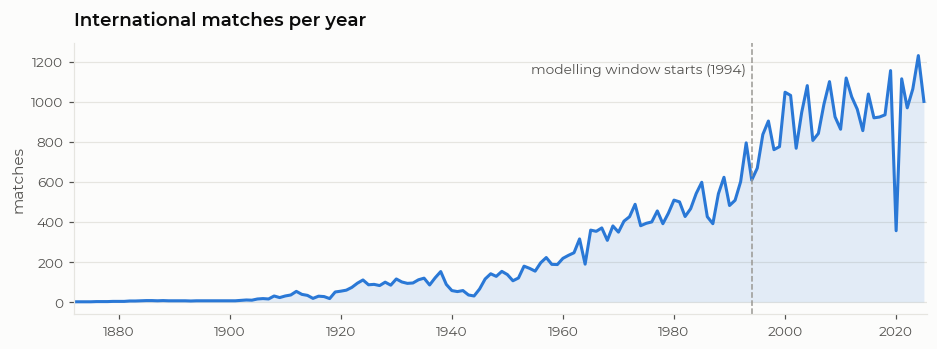

29,837 matches since 1994  |  mean goals per match since 1994: 2.77


In [5]:
per_year = matches[matches.date.dt.year < 2026].groupby(matches.date.dt.year).size()

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.fill_between(per_year.index, per_year.values, color=BLUE, alpha=.12, linewidth=0)
ax.plot(per_year.index, per_year.values, color=BLUE, lw=2)
ax.axvline(TRAIN_START.year, color=MUTED, lw=1, ls='--')
ax.text(TRAIN_START.year - 1, per_year.max() * .97, 'modelling window starts (1994)',
        ha='right', va='top', color=INK_2, fontsize=9)
ax.set(title='International matches per year', ylabel='matches', xlim=(1872, 2025.5))
ax.grid(axis='x', visible=False)
save(fig, '01_matches_per_year'); plt.show()

print(f'{(matches.date >= TRAIN_START).sum():,} matches since 1994  |  '
      f'mean goals per match since 1994: {(matches.home_score + matches.away_score)[matches.date >= TRAIN_START].mean():.2f}')

col_0,Home win,Draw,Away win
row_0,,,
Home team at home,50.9%,23.2%,25.9%
Neutral venue,42.6%,23.4%,34.0%


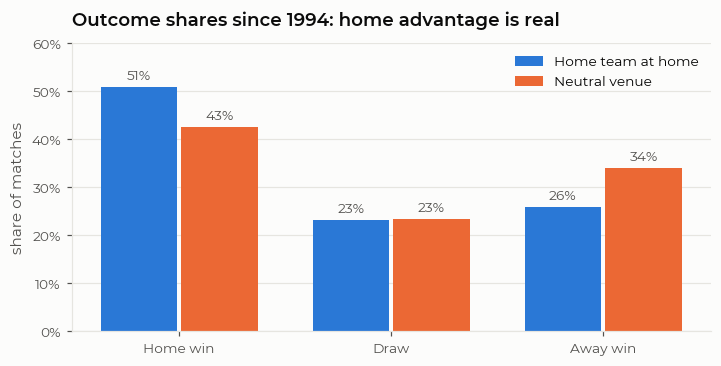

In [6]:
modern = matches[matches.date >= TRAIN_START]
result_label = np.select([modern.home_score > modern.away_score, modern.home_score == modern.away_score],
                         ['Home win', 'Draw'], 'Away win')
venue = np.where(modern.neutral, 'Neutral venue', 'Home team at home')
outcome_share = pd.crosstab(venue, result_label, normalize='index')[['Home win', 'Draw', 'Away win']]
display(outcome_share.style.format('{:.1%}'))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(3); w = .36
for k, (row, color) in enumerate([('Home team at home', BLUE), ('Neutral venue', ORANGE)]):
    vals = outcome_share.loc[row].values
    bars = ax.bar(x + (k - .5) * (w + .02), vals, w, color=color, label=row)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + .01, f'{v:.0%}', ha='center', va='bottom', fontsize=9, color=INK_2)
ax.set_xticks(x, outcome_share.columns)
ax.set(title='Outcome shares since 1994: home advantage is real', ylabel='share of matches', ylim=(0, .6))
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.grid(axis='x', visible=False); ax.legend(loc='upper right')
save(fig, '02_outcome_by_venue'); plt.show()

**Takeaways.**
- The number of internationals has exploded since the 1990s (more federations, Nations Leagues, expanded qualifiers). Training on **1994 onwards** keeps the modern game (3 points per win, current confederation structure) while still giving ~30,000 matches.
- Home advantage is large: the home side wins about half of its home matches, but only ~45% at neutral venues, where the "home" label is just the first-listed team. This motivates an explicit `is_home` feature, and **symmetrising** predictions at neutral World Cup venues (section 9).
- Draws are about a quarter of all results. This is the hardest class to predict, which matters for model choice: we need **well-calibrated probabilities**, not just argmax accuracy.